# 04 · Optimisation des hyperparamètres

Étape 7. Candidat retenu à l'étape 6 : **HistGradientBoosting** (les exemples du guide portent sur LightGBM ; l'espace est adapté aux paramètres de HistGB). Budget : 40 essais par méthode, même métrique (PR-AUC) et même `cv`.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from inclusion_financiere.config import RANDOM_STATE, FIGURES, DECISIONS, COST_FP, COST_FN
from inclusion_financiere.data import load_raw, clean, split, make_cv, CAT_COLS, NUM_COLS

FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)

import json, time
import optuna
from scipy.stats import loguniform, randint, uniform
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV, cross_val_score

from inclusion_financiere.features import pipe

optuna.logging.set_verbosity(optuna.logging.WARNING)

In [2]:
X, y = clean(load_raw())
X_train, X_test, y_train, y_test = split(X, y)
del X_test, y_test  # test sous scellé jusqu'à l'étape 10
cv = make_cv()       # le même objet cv pour tous les modèles
print(X_train.shape, round(y_train.mean(), 4))

dec = json.loads(DECISIONS.read_text())
defaut_moy, defaut_std = dec["histgb_defaut_pr_auc"]
print(f"HistGB par défaut (étape 6) : {defaut_moy:.4f} ± {defaut_std:.4f}")

(18819, 10) 0.1408
HistGB par défaut (étape 6) : 0.5678 ± 0.0284


## 7.1 · Random Search

In [3]:
espace = {
    "histgradientboostingclassifier__learning_rate": loguniform(1e-3, 0.3),
    "histgradientboostingclassifier__max_leaf_nodes": randint(4, 64),
    "histgradientboostingclassifier__min_samples_leaf": randint(5, 200),
    "histgradientboostingclassifier__l2_regularization": loguniform(1e-3, 10),
    "histgradientboostingclassifier__max_features": uniform(0.5, 0.5),   # entre 0,5 et 1
    "histgradientboostingclassifier__max_iter": randint(100, 600),
}
t0 = time.time()
rs = RandomizedSearchCV(pipe(HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
                        espace, n_iter=40, cv=cv, scoring="average_precision",
                        random_state=RANDOM_STATE, n_jobs=-1)
rs.fit(X_train, y_train)
t_rs = time.time() - t0
rs_std = rs.cv_results_["std_test_score"][rs.best_index_]
print(f"{rs.best_score_:.4f} ± {rs_std:.4f} en {t_rs:.0f} s")
{k.split("__")[1]: v for k, v in rs.best_params_.items()}

0.5781 ± 0.0271 en 183 s


{'l2_regularization': np.float64(5.072283440670041),
 'learning_rate': np.float64(0.04100121611923941),
 'max_features': np.float64(0.9574798377718904),
 'max_iter': 300,
 'max_leaf_nodes': 11,
 'min_samples_leaf': 16}

## 7.2 · Optimisation bayésienne avec Optuna (TPE)

In [4]:
def objective(trial):
    params = dict(
        learning_rate=trial.suggest_float("learning_rate", 1e-3, 0.3, log=True),
        max_leaf_nodes=trial.suggest_int("max_leaf_nodes", 4, 64),
        min_samples_leaf=trial.suggest_int("min_samples_leaf", 5, 200, log=True),
        l2_regularization=trial.suggest_float("l2_regularization", 1e-3, 10, log=True),
        max_features=trial.suggest_float("max_features", 0.5, 1.0),
        max_iter=trial.suggest_int("max_iter", 100, 600),
    )
    model = pipe(HistGradientBoostingClassifier(**params, random_state=RANDOM_STATE))
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="average_precision", n_jobs=-1)
    trial.set_user_attr("std", float(scores.std()))
    return scores.mean()


t0 = time.time()
study = optuna.create_study(direction="maximize",
                            sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
study.optimize(objective, n_trials=40)
t_opt = time.time() - t0
print(f"{study.best_value:.4f} ± {study.best_trial.user_attrs['std']:.4f} en {t_opt:.0f} s")
study.best_params

0.5792 ± 0.0255 en 188 s


{'learning_rate': 0.07373313352383347,
 'max_leaf_nodes': 7,
 'min_samples_leaf': 6,
 'l2_regularization': 7.684598675918744,
 'max_features': 0.9931252816724722,
 'max_iter': 327}

## Q7.2 · Gain par rapport aux réglages par défaut

In [5]:
gains = pd.DataFrame([
    {"méthode": "Défaut (étape 6)", "PR-AUC": defaut_moy, "gain": 0.0, "temps (s)": np.nan},
    {"méthode": "Random Search", "PR-AUC": rs.best_score_, "gain": rs.best_score_ - defaut_moy, "temps (s)": t_rs},
    {"méthode": "Optuna (TPE)", "PR-AUC": study.best_value, "gain": study.best_value - defaut_moy, "temps (s)": t_opt},
]).set_index("méthode")
gains["gain en écarts-types"] = gains["gain"] / defaut_std
gains.round(4)

,PR-AUC,gain,temps (s),gain en écarts-types
méthode,,,,
Défaut (étape 6),0.5678,0.0000,NaN,0.0000
Random Search,0.5781,0.0103,182.8493,0.3614
Optuna (TPE),0.5792,0.0114,188.4176,0.4015


**Q7.1** — Pour `learning_rate` (10⁻³ à 0,3) et `l2_regularization` (10⁻³ à 10), c'est l'**ordre de grandeur** qui compte : passer de 0,001 à 0,01 change autant le modèle que passer de 0,01 à 0,1 (slide 51). Un tirage uniforme sur [0,001 ; 0,3] placerait ~97 % des essais au-dessus de 0,01 et n'explorerait presque jamais les petites valeurs. Le tirage log-uniforme répartit le budget de façon égale entre les décades.

**Q7.2** — Par rapport à HistGB par défaut (0,568 ± 0,028) :

| Méthode | Meilleure PR-AUC (CV) | Gain | Gain en écarts-types | Temps |
|---|---|---|---|---|
| Random Search | 0,5781 ± 0,027 | +0,010 | **+0,36** | ~183 s |
| Optuna (TPE) | 0,5792 ± 0,026 | +0,011 | **+0,40** | ~188 s |

Le gain est d'**environ 0,4 écart-type**, et il est **optimiste** : c'est le maximum de 40 essais évalués sur les mêmes plis (Q7.4). Le coût est de ~3 minutes par recherche contre ~5 s pour une CV du modèle par défaut (×40). Les deux recherches convergent vers des configurations voisines : **petits arbres** (7 à 11 feuilles contre 31 par défaut), **forte régularisation L2** (5 à 8), `max_features` proche de 1, ~300 itérations, pas de 0,04 à 0,07. Le réglage valait la peine **ici** parce qu'il est bon marché (3 minutes) et qu'il comble la moitié de l'écart avec CatBoost (0,582) pour un modèle 60 fois plus rapide ; mais le gain n'est pas significatif au regard de la variabilité entre plis, et HistGB par défaut était déjà proche de l'optimum.

## Q7.3 · Meilleur score après 1, 2, …, 40 essais

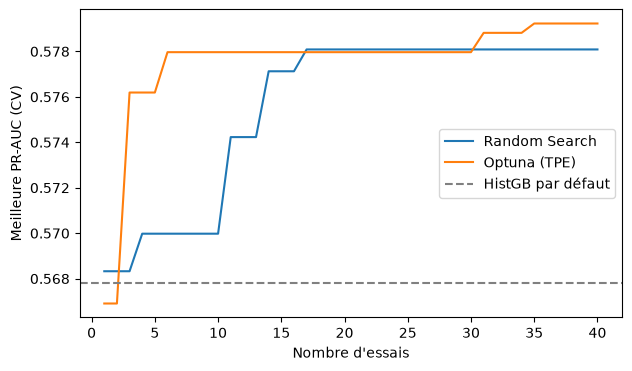

après  5 essais : RS 0.5700 | Optuna 0.5762
après 10 essais : RS 0.5700 | Optuna 0.5780
après 20 essais : RS 0.5781 | Optuna 0.5780
après 40 essais : RS 0.5781 | Optuna 0.5792


In [6]:
rs_best = np.maximum.accumulate(rs.cv_results_["mean_test_score"])
opt_best = np.maximum.accumulate([t.value for t in study.trials])
plt.figure(figsize=(7, 4))
plt.plot(range(1, 41), rs_best, label="Random Search")
plt.plot(range(1, 41), opt_best, label="Optuna (TPE)")
plt.axhline(defaut_moy, color="grey", ls="--", label="HistGB par défaut")
plt.xlabel("Nombre d'essais"); plt.ylabel("Meilleure PR-AUC (CV)"); plt.legend()
plt.savefig(FIGURES / "04_convergence_recherches.png", dpi=120, bbox_inches="tight"); plt.show()
for n in (5, 10, 20, 40):
    print(f"après {n:2d} essais : RS {rs_best[n-1]:.4f} | Optuna {opt_best[n-1]:.4f}")

**Q7.3** — Meilleur score après *n* essais :

| essais | 5 | 10 | 20 | 40 |
|---|---|---|---|---|
| Random Search | 0,5700 | 0,5700 | 0,5781 | 0,5781 |
| Optuna (TPE) | 0,5762 | 0,5780 | 0,5780 | 0,5792 |

**Optuna progresse plus vite au début** (0,578 dès 10 essais, contre 20 pour le Random Search), puis les deux plafonnent et finissent à 0,001 l'un de l'autre. À conclure **avec prudence** (slides 47–48) : par défaut, le TPE d'Optuna tire ses **10 premiers essais au hasard** ; son avance à 5–10 essais relève donc en partie de la chance du tirage, pas de l'optimisation bayésienne. Il n'y a qu'une seule graine et un seul jeu de données, et l'écart final (0,001) est 25 fois plus petit que l'écart-type entre plis. On ne peut pas dire qu'une méthode est meilleure en général ; il faudrait répéter avec plusieurs graines.

**Q7.4** — **Non.** `best_score_` est le **maximum** de 40 moyennes de CV calculées sur les **mêmes plis** qui ont servi à choisir la configuration. Ces plis ont donc servi de jeu de validation pour la sélection : on retient la configuration qui a eu, en partie, de la chance sur ces plis-là, et son score est biaisé vers le haut (biais de sélection, slide 24). Plus on teste de configurations, plus ce biais grandit. Pour une estimation honnête (slide 29) : la **validation croisée imbriquée** (nested CV), où une boucle externe évalue toute la procédure « recherche + réentraînement » sur des plis jamais vus par la recherche ; ou, plus simplement, le **test scellé**, utilisé une seule fois à l'étape 10.

## Q7.5 · Importance des hyperparamètres

max_iter             0.226
max_features         0.213
l2_regularization    0.210
max_leaf_nodes       0.181
learning_rate        0.108
min_samples_leaf     0.061
dtype: float64


C:\Users\diabel\AppData\Local\Temp\ipykernel_25808\2526963566.py:3: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  optuna.visualization.matplotlib.plot_param_importances(study)


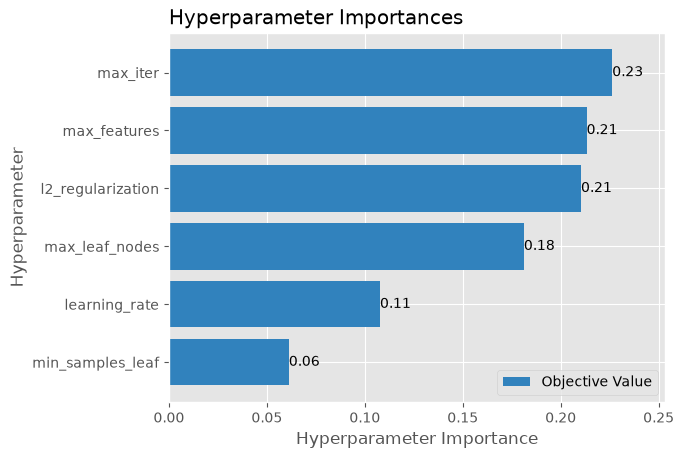

In [7]:
from optuna.importance import get_param_importances
print(pd.Series(get_param_importances(study)).round(3))
optuna.visualization.matplotlib.plot_param_importances(study)
plt.show()

**Q7.5** — Importances (fANOVA d'Optuna) : `max_iter` 0,23, `max_features` 0,21, `l2_regularization` 0,21, `max_leaf_nodes` 0,18, `learning_rate` 0,11, `min_samples_leaf` 0,06. Ici, **aucun hyperparamètre ne domine nettement** : l'importance est assez répartie, ce qui reflète surtout le fait que le paysage est **plat** près de l'optimum (beaucoup de configurations donnent 0,575–0,579) et que 40 essais, concentrés par le TPE dans la bonne zone, donnent une estimation bruitée. Deux remarques : HistGB active l'arrêt anticipé (`early_stopping="auto"` au-delà de 10 000 lignes), donc `max_iter` agit surtout comme un plafond en interaction avec `learning_rate` ; et `min_samples_leaf` compte peu. C'est **partiellement cohérent** avec Bergstra et Bengio (slide 47) : tous les hyperparamètres ne comptent pas autant (`min_samples_leaf` et `learning_rate` pèsent peu ici), et le Random Search, qui essaie une valeur différente de chaque paramètre à chaque essai, n'a pas gaspillé son budget, contrairement à une grille de 40 points sur 6 dimensions (2 valeurs par dimension à peine). Mais on ne voit pas ici le cas d'école « un ou deux paramètres expliquent tout ».

## Bonus · HalvingRandomSearchCV

In [8]:
from sklearn.experimental import enable_halving_search_cv  # noqa: F401
from sklearn.model_selection import HalvingRandomSearchCV

t0 = time.time()
hrs = HalvingRandomSearchCV(pipe(HistGradientBoostingClassifier(random_state=RANDOM_STATE)),
                            espace, n_candidates=40, factor=3, resource="n_samples",
                            cv=cv, scoring="average_precision",
                            random_state=RANDOM_STATE, n_jobs=-1).fit(X_train, y_train)
t_hrs = time.time() - t0
# best_score_ de Halving est mesuré au dernier tour ; on réévalue la config sur tout le train
hrs_score = cross_val_score(hrs.best_estimator_, X_train, y_train, cv=cv,
                            scoring="average_precision", n_jobs=-1)
print(f"Halving : {hrs_score.mean():.4f} ± {hrs_score.std(ddof=1):.4f} en {t_hrs:.0f} s "
      f"(Random Search : {rs.best_score_:.4f} en {t_rs:.0f} s)")

Halving : 0.5672 ± 0.0295 en 26 s (Random Search : 0.5781 en 183 s)


**Bonus** — `HalvingRandomSearchCV` (40 candidats, facteur 3, ressource = nombre de lignes) : **0,567 ± 0,030 en ~26 s**, contre 0,578 en ~183 s pour le Random Search. Sept fois plus rapide, mais il retient ici une configuration **moins bonne** que le défaut : en éliminant les candidats sur de petits sous-échantillons (quelques centaines de lignes au premier tour), il favorise les modèles qui marchent bien avec peu de données, ce qui n'est pas forcément vrai à 15 000 lignes (slide 50). La **nested CV** de la procédure complète (5 plis externes × 40 essais × 5 plis internes ≈ 15 min par méthode) n'a pas été lancée ; l'estimation honnête de la performance est fournie par le test scellé (notebook 06).

## Décision

In [9]:
if study.best_value >= rs.best_score_:
    params_retenus, source = study.best_params, "Optuna"
else:
    params_retenus, source = {k.split("__")[1]: v for k, v in rs.best_params_.items()}, "Random Search"
params_retenus = {k: (int(v) if isinstance(v, (np.integer,)) else v) for k, v in params_retenus.items()}
dec["histgb_params"] = params_retenus
dec["histgb_params_source"] = source
dec["histgb_tuned_pr_auc"] = float(max(study.best_value, rs.best_score_))
DECISIONS.write_text(json.dumps(dec, indent=2))
print(source); params_retenus

Optuna


{'learning_rate': 0.07373313352383347,
 'max_leaf_nodes': 7,
 'min_samples_leaf': 6,
 'l2_regularization': 7.684598675918744,
 'max_features': 0.9931252816724722,
 'max_iter': 327}